# Laboratory #5 : Object Detection with YOLO

At the end of this laboratory, you would get familiarized with

*   Object Detection on Medical Imaging
*   YOLOV5 for Object Detection using Keras and TensorFlow

**Remember this is a graded exercise.**

*   For every plot, make sure you provide appropriate titles, axis labels, legends, wherever applicable.
*   Create reusable functions where ever possible, so that the code could be reused at different places.
*   Add sufficient comments and explanations wherever necessary.
*   **Once you have the code completed, use GPU to train model faster.**

---

## Group
- Ecem Onat Cakmak  
- Michael Eskander  
- Pablo Longán Gasol

In [ ]:
# Mount drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Detection with BCCD dataset

**About the dataset:** BCCD is a small-scale dataset for blood cells detection. It consists of a collection of high-resolution microscope images of blood cell samples (640x480). These images typically showcase a variety of blood cell types under different staining conditions and magnifications.Blodd cells classes are one of three types: Red Blood Cell, White Blood Cell or Platelet. The annotations consists of bounding boxes coordinates for each cell and their classes. There are 364 images with a total of 4888 blood cells annotated

In [ ]:
# Libraries
import os, sys, random, shutil
import xml.etree.ElementTree as ET
from glob import glob
import pandas as pd
from shutil import copyfile
import pandas as pd
from sklearn import preprocessing, model_selection
import matplotlib.pyplot as plt
%matplotlib inline
from matplotlib import patches
import numpy as np

Change the directory to /content/ and clone the github repo: https://github.com/Shenggan/BCCD_Dataset.git

In [ ]:
%cd /content/
!git clone https://github.com/Shenggan/BCCD_Dataset.git

/content
Cloning into 'BCCD_Dataset'...
remote: Enumerating objects: 800, done.
remote: Counting objects: 100% (11/11), done.
remote: Compressing objects: 100% (5/5), done.
remote: Total 800 (delta 8), reused 6 (delta 6), pack-reused 789 (from 1)
Receiving objects: 100% (800/800), 7.39 MiB | 35.18 MiB/s, done.
Resolving deltas: 100% (379/379), done.


The annotations to this dataset come on an .xml format. Run the following code that prepares the annotations and train/validation sets and explain what the code is doing on detail.

In [ ]:
# Obtaining parsed XML into a dataframe for further pre-processing
annotations = sorted(glob('/content/BCCD_Dataset/BCCD/Annotations/*.xml'))

df = []
cnt = 0
for file in annotations:
  prev_filename = file.split('/')[-1].split('.')[0] + '.jpg'
  filename = str(cnt) + '.jpg'
  row = []
  parsedXML = ET.parse(file)
  for node in parsedXML.getroot().iter('object'):
    blood_cells = node.find('name').text
    xmin = int(node.find('bndbox/xmin').text)
    xmax = int(node.find('bndbox/xmax').text)
    ymin = int(node.find('bndbox/ymin').text)
    ymax = int(node.find('bndbox/ymax').text)

    row = [prev_filename, filename, blood_cells, xmin, xmax, ymin, ymax]
    df.append(row)
  cnt += 1

data = pd.DataFrame(df, columns=['prev_filename', 'filename', 'cell_type', 'xmin', 'xmax', 'ymin', 'ymax'])

data[['prev_filename','filename', 'cell_type', 'xmin', 'xmax', 'ymin', 'ymax']].to_csv('/content/blood_cell_detection.csv', index=False)
print(data.shape)
data.head()

(4888, 7)


,prev_filename,filename,cell_type,xmin,xmax,ymin,ymax
0,BloodImage_00000.jpg,0.jpg,WBC,260,491,177,376
1,BloodImage_00000.jpg,0.jpg,RBC,78,184,336,435
2,BloodImage_00000.jpg,0.jpg,RBC,63,169,237,336
3,BloodImage_00000.jpg,0.jpg,RBC,214,320,362,461
4,BloodImage_00000.jpg,0.jpg,RBC,414,506,352,445


In [ ]:
# Data structure required
img_width = 640
img_height = 480

def width(df):
  return int(df.xmax - df.xmin)
def height(df):
  return int(df.ymax - df.ymin)
def x_center(df):
  return int(df.xmin + (df.width/2))
def y_center(df):
  return int(df.ymin + (df.height/2))
def w_norm(df):
  return df/img_width
def h_norm(df):
  return df/img_height

df = pd.read_csv('/content/blood_cell_detection.csv')

le = preprocessing.LabelEncoder()
le.fit(df['cell_type'])
print(le.classes_)
labels = le.transform(df['cell_type'])
df['labels'] = labels

df['width'] = df.apply(width, axis=1)
df['height'] = df.apply(height, axis=1)

df['x_center'] = df.apply(x_center, axis=1)
df['y_center'] = df.apply(y_center, axis=1)

df['x_center_norm'] = df['x_center'].apply(w_norm)
df['width_norm'] = df['width'].apply(w_norm)

df['y_center_norm'] = df['y_center'].apply(h_norm)
df['height_norm'] = df['height'].apply(h_norm)

print(df.shape)

['Platelets' 'RBC' 'WBC']
(4888, 16)


In [ ]:
# Train test split
df_train, df_valid = model_selection.train_test_split(df, test_size=0.1, random_state=13, shuffle=True)
print(df_train.shape, df_valid.shape)

os.mkdir('/content/bcc/')
os.mkdir('/content/bcc/images/')
os.mkdir('/content/bcc/images/train/')
os.mkdir('/content/bcc/images/valid/')

os.mkdir('/content/bcc/labels/')
os.mkdir('/content/bcc/labels/train/')
os.mkdir('/content/bcc/labels/valid/')

def segregate_data(df, img_path, label_path, train_img_path, train_label_path):
  filenames = []
  for filename in df.filename:
    filenames.append(filename)
  filenames = set(filenames)

  for filename in filenames:
    yolo_list = []

    for _,row in df[df.filename == filename].iterrows():
      yolo_list.append([row.labels, row.x_center_norm, row.y_center_norm, row.width_norm, row.height_norm])

    yolo_list = np.array(yolo_list)
    txt_filename = os.path.join(train_label_path,str(row.prev_filename.split('.')[0])+".txt")
    # Save the .img & .txt files to the corresponding train and validation folders
    np.savetxt(txt_filename, yolo_list, fmt=["%d", "%f", "%f", "%f", "%f"])
    shutil.copyfile(os.path.join(img_path,row.prev_filename), os.path.join(train_img_path,row.prev_filename))

## Apply function ##
src_img_path = "/content/BCCD_Dataset/BCCD/JPEGImages/"
src_label_path = "/content/BCCD_Dataset/BCCD/Annotations/"

train_img_path = "/content/bcc/images/train"
train_label_path = "/content/bcc/labels/train"

valid_img_path = "/content/bcc/images/valid"
valid_label_path = "/content/bcc/labels/valid"

segregate_data(df_train, src_img_path, src_label_path, train_img_path, train_label_path)
segregate_data(df_valid, src_img_path, src_label_path, valid_img_path, valid_label_path)

print("No. of Training images", len(os.listdir('/content/bcc/images/train')))
print("No. of Training labels", len(os.listdir('/content/bcc/labels/train')))

print("No. of valid images", len(os.listdir('/content/bcc/images/valid')))
print("No. of valid labels", len(os.listdir('/content/bcc/labels/valid')))

(4399, 16) (489, 16)
No. of Training images 364
No. of Training labels 364
No. of valid images 270
No. of valid labels 270


Explain the code above:

**Solution**

**1. Parse the XML annotations.** Each `.xml` file describes one image. For every `object` tag the code reads the class (`Platelets`, `RBC`, `WBC`) and the box corners (`xmin`, `xmax`, `ymin`, `ymax`). It builds one row per box (4888 boxes in total) with the original filename and a new numbered filename (`0.jpg`, `1.jpg`, ...), and saves everything to `blood_cell_detection.csv`.

**2. Convert to YOLO format.** YOLO does not use corner coordinates. It needs `class x_center y_center width height`, all normalized to 0-1. The code:
* encodes the class names as integers with `LabelEncoder` (Platelets=0, RBC=1, WBC=2),
* computes each box's width, height and center from its corners,
* divides x and width by the image width (640) and y and height by the image height (480).

**3. Train/validation split and folder structure.** The dataframe is split 90/10 at random (`random_state=13` for reproducibility) and the folders `images/train`, `images/valid`, `labels/train` and `labels/valid` are created, as YOLOv5 expects. `segregate_data` then loops over each image in a split and:
* writes a `.txt` label file with one line per box (`class x_c y_c w h`),
* copies the matching `.jpg` image into the same split.


**Limitation**: The split is performed on individual bounding boxes rather than whole images. The saved output shows 364 training images and 270 validation images from a dataset containing only 364 images, so every validation image also appears in training. Furthermore, each split retains only the annotations assigned to it, leaving some visible objects unlabeled. Image overlap can inflate validation performance, while incomplete annotations can cause correct detections to be counted as false positives and affect training. These competing effects make the validation metrics unreliable as estimates of performance on unseen images.

Plot first 5 images with their bounding boxes and display the label of each box (use different colors for different classes). Leverage the dataframe with information regarding class and position of the boxes for each image. matplotlib has a useful function call patches to create the boxes.

Your final outcome for each imge should look similar to this:

![annotated](https://cdn-images-1.medium.com/max/433/1*Nl9tCJfVJfBjLK-7IO_D8A.png)

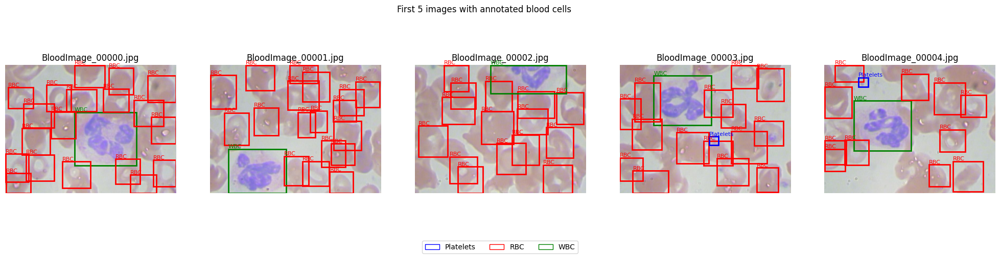

In [ ]:
colors = {"Platelets": "blue", "RBC": "red", "WBC": "green"}
legend = [patches.Patch(edgecolor=c, fill=False, label=k) for k, c in colors.items()]

def draw_boxes(ax, boxes, ls="-", labels=True):
    """Draw bounding boxes (rows of the dataframe) on an axis, colored by class."""
    for _, r in boxes.iterrows():
        c = colors[r.cell_type]
        ax.add_patch(patches.Rectangle((r.xmin, r.ymin), r.width, r.height,
                                       fill=False, edgecolor=c, linewidth=2, linestyle=ls))
        if labels:
            ax.text(r.xmin, r.ymin - 3, r.cell_type, color=c, fontsize=8)

fig, axes = plt.subplots(1, 5, figsize=(25, 5))
for ax, name in zip(axes, df.prev_filename.unique()[:5]):
    ax.imshow(plt.imread(src_img_path + name))
    draw_boxes(ax, df[df.prev_filename == name])
    ax.set_title(name)
    ax.axis("off")
fig.legend(handles=legend, loc="lower center", ncol=3)
fig.suptitle("First 5 images with annotated blood cells")
plt.show()

#### Yolo V5 training

For this dataset, we are going to use YoloV5


First we are going to clone the github repository and install its dependencies. Repo: https://github.com/ultralytics/yolov5.git and requirements are going to be in /content/yolov5/requirements.txt

In [ ]:
!git clone  'https://github.com/ultralytics/yolov5.git'
!pip install -qr '/content/yolov5/requirements.txt'  # install dependencies

Cloning into 'yolov5'...
remote: Enumerating objects: 18875, done.
remote: Counting objects: 100% (427/427), done.
remote: Compressing objects: 100% (257/257), done.
remote: Total 18875 (delta 332), reused 185 (delta 170), pack-reused 18448 (from 2)
Receiving objects: 100% (18875/18875), 17.82 MiB | 27.28 MiB/s, done.
Resolving deltas: 100% (12850/12850), done.


The following code creates a yaml file with some specifications for the training of this data such as train and validation path, classes, etc.

In [ ]:
# Create yaml file
%cd /content/
!echo "train: /content/bcc/images/train" >> bcc.yaml
!echo "val: /content/bcc/images/valid" >> bcc.yaml
!echo "" >> bcc.yaml
!echo "nc: 3" >> bcc.yaml
!echo "" >> bcc.yaml
!echo "names: ['Platelets', 'RBC', 'WBC']" >> bcc.yaml
!cat bcc.yaml

/content
train: /content/bcc/images/train
val: /content/bcc/images/valid

nc: 3

names: ['Platelets', 'RBC', 'WBC']


In [ ]:
# Move yaml into the yolov5 folder
shutil.copyfile('/content/bcc.yaml', '/content/yolov5/bcc.yaml')

'/content/yolov5/bcc.yaml'

In [ ]:
# Edit yaml file to specify categories of model yolov5s
!awk '/nc: 80/{$2="3"}1' /content/yolov5/models/yolov5s.yaml > tmp.yaml && mv tmp.yaml /content/yolov5/models/yolov5s.yaml


Train for 25 epochs with a batch size of 16, make sure to use **tensorboard** to visualize the training process. Here is a starter code for the training call:

```python
!python /content/yolov5/train.py --img value --batch value --epochs value \
    --data bcc.yaml --cfg /content/yolov5/models/yolov5s.yaml --name BCCM
```

Change the "value" to the appropriate one based on the description of the task.

In [ ]:

!sed -i 's/annotator.im.save(fname)/Image.fromarray(annotator.im).save(fname)/' /content/yolov5/utils/plots.py

!python /content/yolov5/train.py --img 640 --batch 16 --epochs 25 --data bcc.yaml --cfg /content/yolov5/models/yolov5s.yaml --name BCCM

%load_ext tensorboard
%tensorboard --logdir /content/yolov5/runs/train

WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1793792449.396277    5222 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice: (30 second timeout) 
wandb: WARNING W&B disabled due to login timeout.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin
train: weights=yolov5/yolov5s.pt, cfg=/content/yolov5/models/yolov5s.yaml, data=bcc.yaml, hyp=yolov5/data/hyps/hyp.scratch-low.yaml, epochs=25, batch_size=16, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=yolov5/data/hyps, resume_evolve=None, bucket=, cache=None, image_weights=False, device=, multi_scale=False, single_cls=False, optimizer=SGD, 

<IPython.core.display.Javascript object>

Comment on your results: What is the current accuracy? Is this a good performance level?

**Solution**


* Precision = 0.136 , Recall = 0.792
* mAP@50 = 0.163, mAP@50-95 = 0.101

This is a low performance level. The provided code splits the annotations (boxes) instead of the images, so each validation image keeps only about 10% of its labels. The model's correct detections of the unlabeled cells count as false positives, which gives a very low precision, while recall stays high (0.79) because most labeled cells are found. Splitting by image would give complete labels and more reliable metrics.

**Inference:**

 Predict /content/bcc/images/valid/BloodImage_00000.jpg images and **plot** its results (this is created and saved at the yolov5/runs/detect/exp directory).

 Hint: To predict, there is a /content/yolov5/detect.py scripts. You can specify the image to predict, the weights yolov5/runs/train/weights/best.pt and save the results as txt.


detect: weights=['/content/yolov5/runs/train/BCCM/weights/best.pt'], source=/content/bcc/images/valid/BloodImage_00000.jpg, data=yolov5/data/coco128.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=True, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=yolov5/runs/detect, name=exp, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-569-g9777cd00 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
YOLOv5s summary: 68 layers, 7,018,216 parameters, 0 gradients, 15.8 GFLOPs
image 1/1 /content/bcc/images/valid/BloodImage_00000.jpg: 480x640 23 RBCs, 1 WBC, 43.3ms
Speed: 0.6ms pre-process, 43.3ms inference, 61.9ms NMS per image at shape (1, 3, 640, 640)
Results saved to yolov5/runs/detect/exp
1 labels saved to yolov5/runs/detect/exp/labels


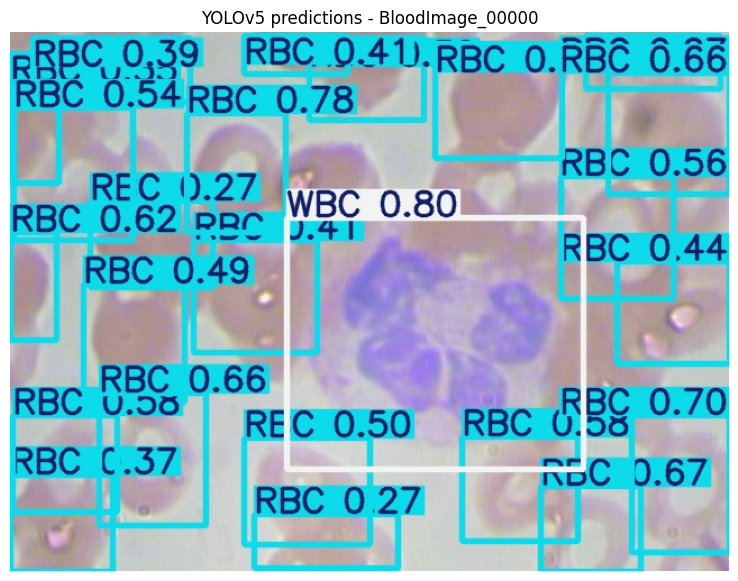

In [ ]:
!python /content/yolov5/detect.py --weights /content/yolov5/runs/train/BCCM/weights/best.pt --img 640 --source /content/bcc/images/valid/BloodImage_00000.jpg --save-txt

pred = plt.imread("/content/yolov5/runs/detect/exp/BloodImage_00000.jpg")
plt.figure(figsize=(10, 7))
plt.imshow(pred)
plt.title("YOLOv5 predictions - BloodImage_00000")
plt.axis("off")
plt.show()

Compare the provided annotations to the resulted ones by visually overlaying the original boxes over the predicted image you just plotted.


*   Load and display the image with the predictions
*   Overlay the actual annotations as you already did



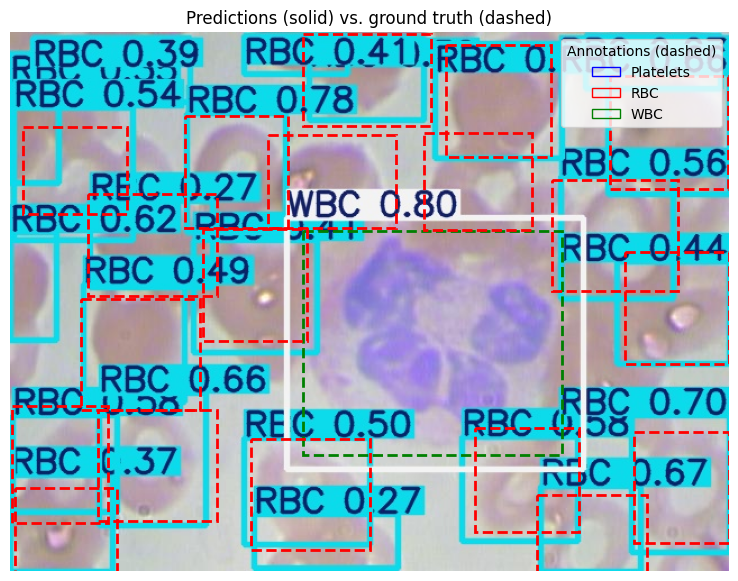

In [ ]:
# Dashed boxes = ground-truth annotations, drawn over the predicted image
fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(pred)
draw_boxes(ax, df[df.prev_filename == "BloodImage_00000.jpg"], ls="--", labels=False)
ax.legend(handles=legend, title="Annotations (dashed)")
ax.set_title("Predictions (solid) vs. ground truth (dashed)")
ax.axis("off")
plt.show()

The predicted boxes locate the prominent WBC and many RBCs, but several RBC predictions overlap or differ in position and size from the original annotations. This example illustrates both successful localization and remaining detection errors.

Run consistency limitation: The saved training metrics come from the BCCM2 run, whereas the inference command loads weights from BCCM. The visualization therefore illustrates predictions from an earlier run and should not be treated as a direct visual evaluation of the model producing the reported metrics. The selected image also appears in training, so it does not demonstrate performance on an unseen image.

# Understanding Object Detection

*   What is the latest YOLO version available in literature? Provide a brief summary of this version

**Solution**

As of November 2026, the newest YOLO release is **YOLO26** from Ultralytics (paper on arXiv in September 2025, official launch in January 2026). It is designed for fast, efficient inference on edge devices. Main features:
* **NMS-free, end-to-end inference:** it outputs the final detections directly, without the non-maximum suppression post-processing step.
* **No Distribution Focal Loss (DFL):** this simplifies the box head and makes export (ONNX, TensorRT, CoreML, TFLite) easier.
* **ProgLoss and STAL:** a progressive loss balancing and a small-target-aware label assignment that improve small-object detection.
* **MuSGD optimizer:** a hybrid of SGD and Muon for faster, more stable training.
* **Speed:** up to ~43% faster CPU inference for the nano model; one design covers detection, segmentation, pose, oriented boxes and classification.
* **Accuracy on COCO:** from 40.9 mAP@50-90 (nano) to 57.5 (extra large).

Sources: Ultralytics. (n.d.). Ultralytics YOLO26. Retrieved November 5, 2026, from https://docs.ultralytics.com/models/yolo26/

*   What are the other object detection frameworks available in the literature?

**Solution**

* **Two-stage detectors:** R-CNN, Fast R-CNN, Faster R-CNN, Mask R-CNN (propose regions first, then classify them; more accurate but slower).
* **One-stage detectors:** the YOLO family, SSD, RetinaNet, EfficientDet (predict boxes and classes in one pass; faster).
* **Anchor-free detectors:** CornerNet, CenterNet, FCOS.
* **Transformer-based detectors:** DETR, Deformable DETR, RT-DETR.

*   What are the drawbacks in object detection frameworks?

**Solution**

* **Small, crowded or overlapping objects** are hard to detect (like platelets or touching cells here).
* **Speed vs. accuracy trade-off:** accurate models are heavy, fast models lose accuracy.
* **Large labeled datasets are needed**, and bounding-box annotation is expensive, especially in medical imaging.
* **Class imbalance:** frequent classes (RBC here) dominate training.
* **Sensitive to post-processing and thresholds** such as NMS and confidence/IoU thresholds (except in NMS-free models).
* **Poor generalization to a new domain** (different microscope, staining or lighting).
* **Hardware cost:** training needs a GPU, and deployment on edge devices requires optimization.

*   Explain the performance metrics used over this notebook. What values reflect good performance?

**Solution**

* **IoU (Intersection over Union):** overlap between a predicted box and the true box divided by their union. A detection counts as correct if IoU is above a threshold (usually 0.5).
* **Precision:** share of predicted boxes that are correct (TP / (TP + FP)).
* **Recall:** share of true objects that were found (TP / (TP + FN)).
* **AP / mAP:** area under the precision-recall curve for one class, averaged over classes for mAP. **mAP@50** uses IoU 0.5 and **mAP@50-95** averages over IoU thresholds from 0.5 to 0.95 (a stricter measure of box quality).
* **Losses** (`box_loss`, `obj_loss`, `cls_loss`): box position error, objectness error and classification error. They should decrease during training.

Values close to 1 are better. As a rough guide, mAP@50 above 0.8-0.9 is good, while mAP@50-95 is naturally lower (0.5-0.7 is good for many tasks).


---

# **End of Object Detection with YOLO**
Deadline forsubmission in CampusVirtual is: **7 november 2024**